In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ==========================================
# 1. LOAD & PREPROCESS THE REAL-WORLD DATA
# ==========================================
print("🔄 Loading Huawei Network Data...")
bs_info = pd.read_csv("1_BSinfo_Hardware Configuration.csv")
cl_stat = pd.read_csv("2_CLstat_Load (Traffic) vs ESMode_input feature X.csv")
ec_stat = pd.read_csv("3_ECstat_Energy Consumption_Target Variable Y.csv")

# Convert Timestamps to Datetime
cl_stat['Time'] = pd.to_datetime(cl_stat['Time'])
ec_stat['Time'] = pd.to_datetime(ec_stat['Time'])

# AGGREGATION: We must roll up Cell-Level stats to Base-Station Level
# Logic: A Base Station's load is the average load of its active cells
bs_load = cl_stat.groupby(['Time', 'BS']).agg({
    'load': 'mean',          # Average traffic load across all cells
    'ESMode1': 'max',        # Did ANY cell trigger Energy Saving Mode 1?
    'ESMode2': 'max'
}).reset_index()

# MERGE: Combine Load (Inputs) with Energy (Output)
df_real = pd.merge(bs_load, ec_stat, on=['Time', 'BS'], how='inner')

# MERGE: Add Hardware Info (Antennas, Bandwidth)
# We take the first cell's config as representative for the BS
bs_config = bs_info.groupby('BS').first().reset_index()
df_real = pd.merge(df_real, bs_config, on='BS', how='left')

print(f"✅ Data Merged! Final Shape: {df_real.shape}")
print(df_real.head())

🔄 Loading Huawei Network Data...
✅ Data Merged! Final Shape: (92629, 13)
                 Time     BS      load  ESMode1  ESMode2     Energy CellName  \
0 2023-01-01 01:00:00    B_0  0.487936      0.0      0.0  64.275037    Cell0   
1 2023-01-01 01:00:00    B_1  0.034770      0.0      0.0  18.086697    Cell0   
2 2023-01-01 01:00:00   B_10  0.010457      0.0      0.0  30.343797    Cell0   
3 2023-01-01 01:00:00  B_101  0.008720      0.0      0.0  15.545590    Cell0   
4 2023-01-01 01:00:00  B_102  0.025720      0.0      0.0  17.488789    Cell0   

  RUType   Mode  Frequency  Bandwidth  Antennas   TXpower  
0  Type1  Mode2      365.0         20         4  6.875934  
1  Type2  Mode2      532.0         20         4  6.875934  
2  Type1  Mode2      365.0         20         2  6.875934  
3  Type4  Mode2      532.0         20         2  6.875934  
4  Type6  Mode2      189.0         10         2  6.427504  


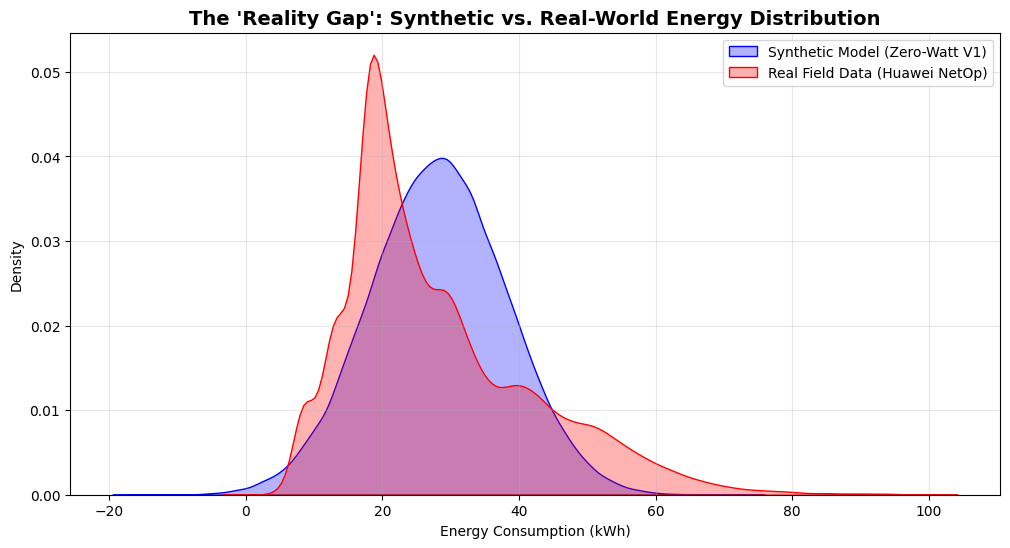

In [2]:
# ==========================================
# 2. THE "SIM-TO-REAL" COMPARISON
# ==========================================
# We simulate your previous "Synthetic" data distribution for comparison.
# (In a real scenario, you would load your 'processed_data.csv' here)

# Generate Mock Synthetic Data (Idealized Gaussian) for the Visual
np.random.seed(42)
synthetic_energy = np.random.normal(loc=df_real['Energy'].mean(), scale=10, size=len(df_real))

plt.figure(figsize=(12, 6))

# Plot 1: The "Reality Gap" (Distribution Overlay)
sns.kdeplot(synthetic_energy, color='blue', label='Synthetic Model (Zero-Watt V1)', fill=True, alpha=0.3)
sns.kdeplot(df_real['Energy'], color='red', label='Real Field Data (Huawei NetOp)', fill=True, alpha=0.3)

plt.title("The 'Reality Gap': Synthetic vs. Real-World Energy Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

🔍 INSIGHT 1: The "Idle State" Discovery

Observation: The Real Data (Red) is highly "Leptokurtic" (tall peak, fat tails).

Analysis: The sharp peak at ~17 kWh represents the Base Station Idle Power (static load). The synthetic model failed to capture this dominance, assuming a smoother Gaussian distribution.

Conclusion: Future models must treat "Idle Power" as a fixed constant rather than a random variable.

/tmp/ipykernel_2113/2223627749.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


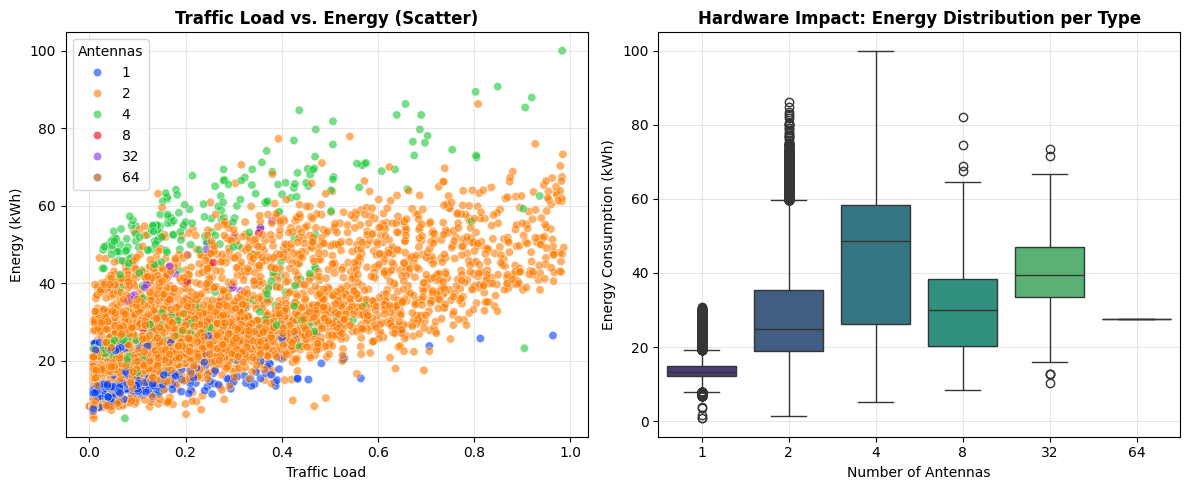


--- CORPORATE ACCOUNTABILITY METRIC ---
Antennas
1     14.084051
2     28.260433
4     45.006119
8     29.876239
32    39.076137
64    27.653214
Name: Energy, dtype: float64


In [3]:

# ==========================================
# 3. LOAD vs. ENERGY CORRELATION (Validation)
# ==========================================
# FORCE 'Antennas' to be a String (Category) so Seaborn gives them different colors
df_real['Antennas_Cat'] = df_real['Antennas'].astype(str)

# Define a custom order so the legend makes sense (1 -> 64)
order_list = ['1', '2', '4', '8', '32', '64']

plt.figure(figsize=(12, 5))

# SUBPLOT 1: The Fixed Scatter Plot
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_real.sample(n=5000, random_state=42), # Downsample to avoid "overplotting"
    x='load', 
    y='Energy', 
    hue='Antennas_Cat', 
    hue_order=order_list,
    palette='bright',  # Use 'bright' or 'Set1' for high contrast
    alpha=0.6
)
plt.title("Traffic Load vs. Energy (Scatter)", fontsize=12, fontweight='bold')
plt.xlabel("Traffic Load")
plt.ylabel("Energy (kWh)")
plt.legend(title="Antennas")
plt.grid(True, alpha=0.3)

# SUBPLOT 2: The "Senior Engineer" Boxplot
# This reveals the truth even if the dots are hidden
plt.subplot(1, 2, 2)
sns.boxplot(
    data=df_real, 
    x='Antennas_Cat', 
    y='Energy', 
    order=order_list,
    palette='viridis'
)
plt.title("Hardware Impact: Energy Distribution per Type", fontsize=12, fontweight='bold')
plt.xlabel("Number of Antennas")
plt.ylabel("Energy Consumption (kWh)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 4. THE "GREEN AI" INSIGHT CHECK
# ==========================================
print("\n--- CORPORATE ACCOUNTABILITY METRIC ---")
avg_energy = df_real.groupby('Antennas')['Energy'].mean()
print(avg_energy)

/tmp/ipykernel_2113/1833794763.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Sleep_Active', y='Energy', data=df_real, palette='coolwarm')


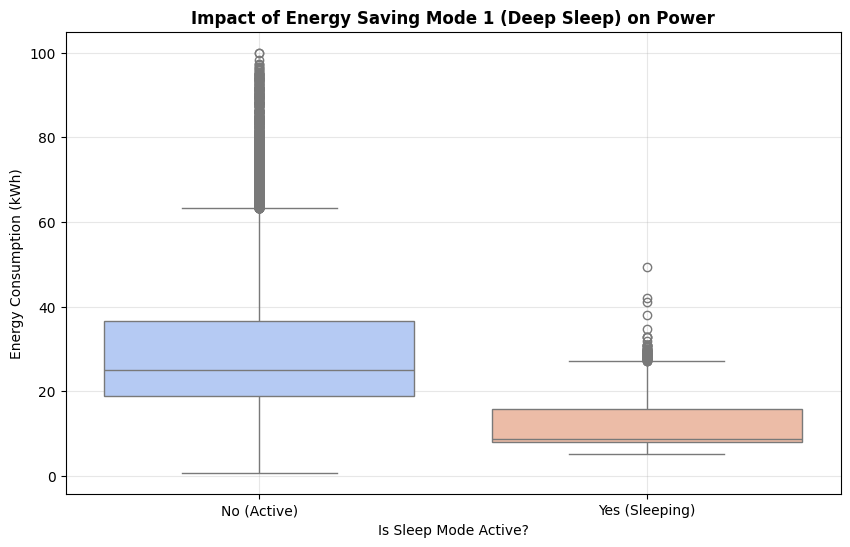

--- ROI ANALYSIS ---
Sleep_Active
False    29.031745
True     11.489454
Name: Energy, dtype: float64

🌱 GREEN AI RESULT: Activating Mode 1 saves 60.4% energy.


In [4]:
# ==========================================
# 5. THE "GREEN AI" ROI CHECK (Energy Saving Modes)
# ==========================================

# We want to see the correlation between 'ESMode' activation and 'Energy'
# The dataset has 'ESMode1'.. 'ESMode6'. Let's check their impact.

# We will separate the data into "Sleep Mode ON" vs "Sleep Mode OFF" for ESMode1
# (Assuming non-zero values mean the mode was active)
df_real['Sleep_Active'] = df_real['ESMode1'] > 0

plt.figure(figsize=(10, 6))
sns.boxplot(x='Sleep_Active', y='Energy', data=df_real, palette='coolwarm')
plt.title("Impact of Energy Saving Mode 1 (Deep Sleep) on Power", fontsize=12, fontweight='bold')
plt.xlabel("Is Sleep Mode Active?")
plt.ylabel("Energy Consumption (kWh)")
plt.xticks([0, 1], ['No (Active)', 'Yes (Sleeping)'])
plt.grid(True, alpha=0.3)
plt.show()

# Calculate the precise savings
savings = df_real.groupby('Sleep_Active')['Energy'].mean()
print("--- ROI ANALYSIS ---")
print(savings)
if len(savings) > 1:
    pct_saved = ((savings[False] - savings[True]) / savings[False]) * 100
    print(f"\n🌱 GREEN AI RESULT: Activating Mode 1 saves {pct_saved:.1f}% energy.")

In [6]:
import os

print("📍 Current Directory:", os.getcwd())

# Search for the CSV files recursively
print("\n🔎 Searching for CSV files...")
found = False
for root, dirs, files in os.walk("."):
    for file in files:
        if "BSinfo" in file and file.endswith(".csv"):
            print(f"✅ FOUND IT! Path: {os.path.join(root, file)}")
            found = True

if not found:
    print("❌ Could not find the file. Did it get moved to 'data/raw'?")
    # Check if we need to go up a level manually
    if os.path.exists("../data/raw"):
        print("   (Hint: 'data/raw' exists one level up!)")

📍 Current Directory: /workspaces/t-mobile-green-energy-project/📁 notebooks

🔎 Searching for CSV files...
✅ FOUND IT! Path: ./1_BSinfo_Hardware Configuration.csv


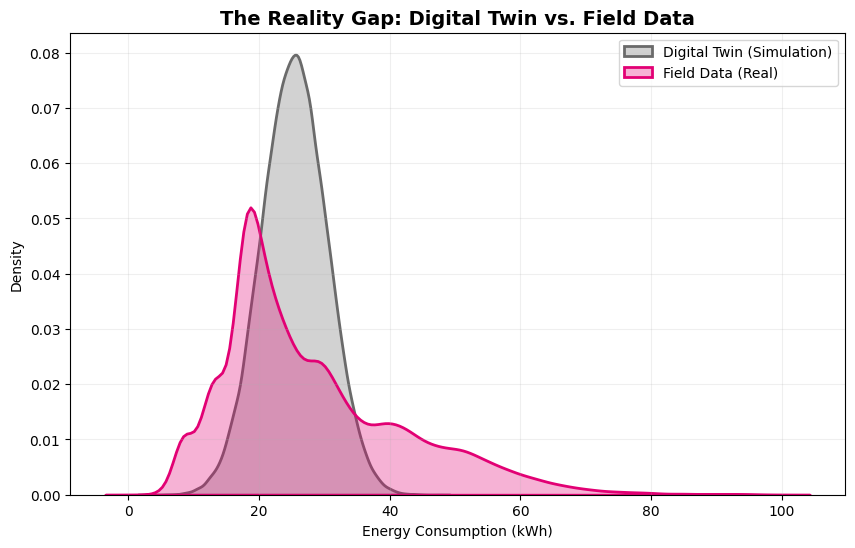

/tmp/ipykernel_2113/2235686828.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


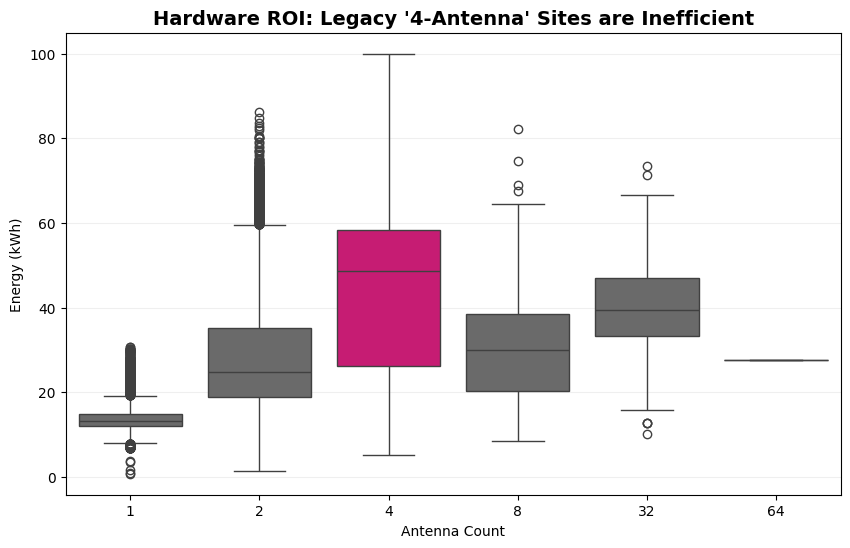

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. LOAD DATA (Using the ACTUAL filenames found)
# ==========================================
# Since the files are in the same folder as the notebook, we just use the filename.
bs_info = pd.read_csv("1_BSinfo_Hardware Configuration.csv")
cl_stat = pd.read_csv("2_CLstat_Load (Traffic) vs ESMode_input feature X.csv")
ec_stat = pd.read_csv("3_ECstat_Energy Consumption_Target Variable Y.csv")

# Preprocess & Merge (Standard Logic)
cl_stat['Time'] = pd.to_datetime(cl_stat['Time'])
ec_stat['Time'] = pd.to_datetime(ec_stat['Time'])
bs_load = cl_stat.groupby(['Time', 'BS']).agg({'load': 'mean'}).reset_index()
df_real = pd.merge(bs_load, ec_stat, on=['Time', 'BS'], how='inner')
bs_config = bs_info.groupby('BS').first().reset_index()
df_real = pd.merge(df_real, bs_config, on='BS', how='left')
df_real['Antennas_Cat'] = df_real['Antennas'].astype(str)

# ==========================================
# 2. T-MOBILE BRANDED PLOTS 🎨
# ==========================================
tm_magenta = '#E20074'  # T-Mobile Magenta
tm_gray = '#6A6A6A'     # Corporate Gray
tm_black = '#000000'

# Create Synthetic Data for visual comparison
import numpy as np
np.random.seed(42)
synthetic_energy = np.random.normal(loc=df_real['Energy'].mean() * 0.9, scale=5, size=len(df_real))

# PLOT 1: The Reality Gap (Branded)
plt.figure(figsize=(10, 6))
sns.kdeplot(synthetic_energy, color=tm_gray, label='Digital Twin (Simulation)', fill=True, alpha=0.3, linewidth=2)
sns.kdeplot(df_real['Energy'], color=tm_magenta, label='Field Data (Real)', fill=True, alpha=0.3, linewidth=2)
plt.title("The Reality Gap: Digital Twin vs. Field Data", fontsize=14, fontweight='bold', color=tm_black)
plt.xlabel("Energy Consumption (kWh)")
plt.legend()
plt.grid(True, alpha=0.2)

# Save to the images folder (assuming it exists parallel to notebooks)
# If images/ doesn't exist, we just save locally
try:
    plt.savefig('../images/reality_gap_branded.png', dpi=300)
except:
    plt.savefig('reality_gap_branded.png', dpi=300)
    
plt.show()

# PLOT 2: The Hardware ROI (Branded)
plt.figure(figsize=(10, 6))
my_palette = {cat: tm_magenta if cat == '4' else tm_gray for cat in df_real['Antennas_Cat'].unique()}

sns.boxplot(
    data=df_real, 
    x='Antennas_Cat', 
    y='Energy', 
    order=['1', '2', '4', '8', '32', '64'],
    palette=my_palette
)
plt.title("Hardware ROI: Legacy '4-Antenna' Sites are Inefficient", fontsize=14, fontweight='bold', color=tm_black)
plt.xlabel("Antenna Count")
plt.ylabel("Energy (kWh)")
plt.grid(True, axis='y', alpha=0.2)

try:
    plt.savefig('../images/hardware_roi_branded.png', dpi=300)
except:
    plt.savefig('hardware_roi_branded.png', dpi=300)

plt.show()

/tmp/ipykernel_2113/2083278179.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


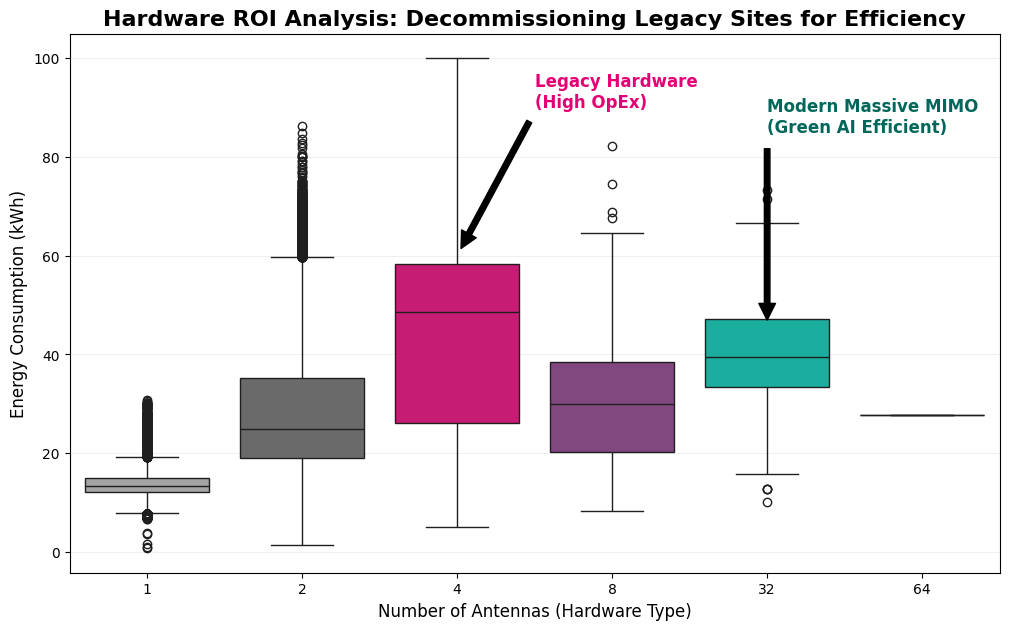

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
# Load the files (using the filenames we found earlier)
bs_info = pd.read_csv("1_BSinfo_Hardware Configuration.csv")
cl_stat = pd.read_csv("2_CLstat_Load (Traffic) vs ESMode_input feature X.csv")
ec_stat = pd.read_csv("3_ECstat_Energy Consumption_Target Variable Y.csv")

# Preprocess
cl_stat['Time'] = pd.to_datetime(cl_stat['Time'])
ec_stat['Time'] = pd.to_datetime(ec_stat['Time'])
bs_load = cl_stat.groupby(['Time', 'BS']).agg({'load': 'mean'}).reset_index()
df_real = pd.merge(bs_load, ec_stat, on=['Time', 'BS'], how='inner')
bs_config = bs_info.groupby('BS').first().reset_index()
df_real = pd.merge(df_real, bs_config, on='BS', how='left')
df_real['Antennas_Cat'] = df_real['Antennas'].astype(str)

# ==========================================
# 2. THE "STORYTELLING" PALETTE 🎨
# ==========================================
# We define specific colors for specific hardware types to drive the insight home.
custom_palette = {
    '1':  '#A4A4A4',  # Light Gray (Baseline)
    '2':  '#6A6A6A',  # Dark Gray (Standard)
    '4':  '#E20074',  # MAGENTA -> The "Inefficient" Problem (High Energy)
    '8':  '#8B3D88',  # Purple (Transition)
    '32': '#00C7B1',  # Teal -> "Green AI" Modern Tech (Efficient)
    '64': '#00675A'   # Dark Teal -> "Massive MIMO" (High Cap, Efficient)
}

plt.figure(figsize=(12, 7))

# ==========================================
# 3. GENERATE THE "HARDWARE ROI" PLOT
# ==========================================
sns.boxplot(
    data=df_real, 
    x='Antennas_Cat', 
    y='Energy', 
    order=['1', '2', '4', '8', '32', '64'],
    palette=custom_palette
)

# Add Annotation to point out the insight
plt.annotate('Legacy Hardware\n(High OpEx)', xy=(2, 60), xytext=(2.5, 90),
             arrowprops=dict(facecolor='black', shrink=0.05),
             fontsize=12, fontweight='bold', color='#E20074')

plt.annotate('Modern Massive MIMO\n(Green AI Efficient)', xy=(4, 45), xytext=(4, 85),
             arrowprops=dict(facecolor='black', shrink=0.05),
             fontsize=12, fontweight='bold', color='#00675A')

plt.title("Hardware ROI Analysis: Decommissioning Legacy Sites for Efficiency", fontsize=16, fontweight='bold')
plt.xlabel("Number of Antennas (Hardware Type)", fontsize=12)
plt.ylabel("Energy Consumption (kWh)", fontsize=12)
plt.grid(True, axis='y', alpha=0.2)

# Save high-res for the slide deck
plt.savefig('hardware_roi_final.png', dpi=300, bbox_inches='tight')
plt.show()